### Tumor Zone Selection
Figure 4A

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import cv2

In [ ]:
# read in annotation and do some formate matching
data_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/PDAC/annotations'
cell_table = pd.read_csv(os.path.join(data_dir, 'annotations_2023-08-17_FINAL.csv'))

In [ ]:
# tide up the spreadsheet
# renaming columns to make them align with the original design
cell_table = cell_table.rename(columns={"cellLabel": "label", 
                                        "path": "fov", 
                                        "cellSize": "cell_size",
                                        "cellType": "cell_cluster",
                                        "X_cent": "centroid-0",
                                        "Y_cent": "centroid-1"}, errors="raise")

# they suggest to include more levels of granularity for cell_cluster
cell_table['cell_cluster_broad'] = cell_table['cell_cluster'].replace({'CD4': 'T',
                                                                       'CD8': 'T',
                                                                       'Lymphatic': 'T',
                                                                       'Treg': 'T',
                                                                       'Plasmablast': 'B',
                                                                       'M1': 'Mono_Mac',
                                                                       'M2': 'Mono_Mac',
                                                                       'Monocyte': 'Mono_Mac'
                                                                       })

# they somehow have both "area" and "cell_size", and those two are the same thing, I just create a duplicate
cell_table['area'] = cell_table.loc[:, 'cell_size']

# remove columns that not useful anymore
cell_table = cell_table.drop(columns=['PG1', 'PG1.annot', 'PG2',
       'PG2.annot', 'FSOM3', 'FSOM3.annot', 'PG4', 'PG4.annot', 'PG5',
       'PG5.annot', 'PG6', 'PG6.annot', 'FSOM7', 'FSOM7.annot', 'FSOM7.1',
       'FSOM7.1.annot', 'FSOM7.2', 'FSOM7.2.annot', 'FSOM8', 'FSOM8.annot',
       'FSOM8.1', 'FSOM8.1.annot', 'FSOM9', 'FSOM9.annot', 'FSOM10',
       'FSOM10.annot', 'FSOM11', 'FSOM11.annot', 'FSOM12', 'FSOM12.annot',
       'FSOM13', 'FSOM13.annot', 'FSOM14', 'FSOM14.annot', 'circled'])

# fix an error about the BMS_E2547_S1_R1 was written as BMS_E2457_S1_R1
cell_table = cell_table.replace({'fov': {'2022-10-06T23-07-14_BMS_E2457_S1_R1_tile5x5':'2022-10-06T23-07-14_BMS_E2547_S1_R1_tile5x5',
                                         '2022-10-06T23-07-14_BMS_E2457_S1_R2_tile5x5':'2022-10-06T23-07-14_BMS_E2547_S1_R2_tile5x5'}})

In [ ]:
# only get the tumor cells out for the downstream analysis
tumor_table = cell_table[cell_table['cell_cluster']=='Tumor']

In [ ]:
# Further divide the dataset into each FOV
# for each FOV, read in the corresponding cell segmentation mask
Keratin_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/TIFFs_allprocessed'
seg_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/20221207_celegene_data_delivery/Segmentation'
out_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/_Tumor_selection/tumor_masks'
FOVs = tumor_table['fov'].unique()

# for testing parameters, etc
#FOVs = ['2022-09-12T15-16-51_BMS_Pt3_S3_R2_tile5x5']

# Define a structuring element (kernel) for image closing operation. 
kernel = np.ones((10, 10), np.uint8)

for FOV in FOVs:
    # find the cellID of current tumor cells
    curr_tumor_table = tumor_table[tumor_table['fov']==FOV]
    curr_tumor_array = curr_tumor_table['label'].to_numpy()
    
    # open the segmentation mask
    curr_seg_mask = Image.open(os.path.join(seg_dir, FOV, 'MESMER_mask.tiff'))
    curr_seg_mask = np.array(curr_seg_mask)
    
    # use the annotation to light-up all tumor cells
    tumor_mask = np.isin(curr_seg_mask, curr_tumor_array).astype(np.uint8)
    # Perform morphological closing
    binary_tumor_image_closed = cv2.morphologyEx(tumor_mask, cv2.MORPH_CLOSE, kernel).astype(np.uint8)

    # open the Keratin image
    Ker_map = Image.open(os.path.join(Keratin_dir, FOV, 'keratin_mix.tiff'))
    Ker_map = np.array(Ker_map).astype(np.uint16)
    
    # Apply Otsu's thresholding to binarize the image
    #otsu_threshold, binary_Ker_image = cv2.threshold(Ker_map, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # Apply fixed value to binarize the image
    threshold_value = 20
    ret, binary_Ker_image = cv2.threshold(Ker_map, threshold_value, 1, cv2.THRESH_BINARY)
    
    # remove regions that are too small
    # Set your minimum area threshold (adjust as needed)
    min_area = 100  # For example, remove regions smaller than 100 pixels
    Ker_num_labels, Ker_labels, Ker_stats, Ker_centroids = cv2.connectedComponentsWithStats(binary_Ker_image.astype(np.uint8), connectivity=8)
    # Create an empty image to hold the filtered regions
    Ker_filtered_map = np.zeros_like(binary_Ker_image)
    # Iterate over each region (skip label 0 which is the background)
    for label in range(1, Ker_num_labels):
        Ker_area = Ker_stats[label, cv2.CC_STAT_AREA]
        if Ker_area >= min_area:
            # Set pixels of this region to 1 (foreground)
            Ker_filtered_map[Ker_labels == label] = 1
    
    # fill the holes of Keratin image
    # Perform morphological closing
    binary_Ker_image_closed = cv2.morphologyEx(Ker_filtered_map, cv2.MORPH_CLOSE, kernel).astype(np.uint8)
    
    # remove regions that are too small
    # Set your minimum area threshold (adjust as needed)
    min_area = 100  # For example, remove regions smaller than 100 pixels
    Ker_num_labels, Ker_labels, Ker_stats, Ker_centroids = cv2.connectedComponentsWithStats(binary_Ker_image_closed.astype(np.uint8), connectivity=8)
    # Create an empty image to hold the filtered regions
    Ker_filtered_map2 = np.zeros_like(binary_Ker_image_closed)
    
    portion_threshold = 0.2
    # Iterate over each region (skip label 0 which is the background)
    for label in range(1, Ker_num_labels):
        # Create a boolean mask for the current region
        region_mask = (Ker_labels == label)

        # Total number of pixels in the region
        region_area = np.sum(region_mask)

        # Count how many pixels in the region are positive in binary_map2
        # (assuming positive means pixel value 1)
        overlap_pixels = np.sum((binary_tumor_image_closed == 1) & region_mask)

        # Calculate the fraction of the region that is positive in binary_map2
        overlap_ratio = overlap_pixels / region_area
        #print(overlap_ratio)

        # If the overlap ratio exceeds the threshold, keep this region in the output
        if overlap_ratio >= portion_threshold:
            Ker_filtered_map2[region_mask] = 1
    
    # Overlay the two maps together to get the final mask
    ROI_selected = Ker_filtered_map2 + binary_tumor_image_closed
    ROI_selected[ROI_selected>1] = 1
    
    # remove regions that are too small
    # Set your minimum area threshold (adjust as needed)
    min_area = 200  # For example, remove regions smaller than 100 pixels
    ROI_num_labels, ROI_labels, ROI_stats, ROI_centroids = cv2.connectedComponentsWithStats(ROI_selected, connectivity=8)
    # Create an empty image to hold the filtered regions
    ROI_filtered_map = np.zeros_like(ROI_selected)
    # Iterate over each region (skip label 0 which is the background)
    for label in range(1, ROI_num_labels):
        ROI_area = ROI_stats[label, cv2.CC_STAT_AREA]
        if ROI_area >= min_area:
            # Set pixels of this region to 1 (foreground)
            ROI_filtered_map[ROI_labels == label] = 1
    
    # flood fill the image, lets only consider buffer towards the outside
    
    # Make a copy for flood filling
    ROI_floodfill = ROI_filtered_map.copy()

    # Create a mask for floodFill (note: it needs 2 extra pixels in width and height)
    h, w = ROI_filtered_map.shape[:2]
    floodfill_mask = np.zeros((h + 2, w + 2), np.uint8)

    # Flood fill from the top-left corner (which should be part of the background)
    cv2.floodFill(ROI_floodfill, floodfill_mask, (0, 0), 1)

    # Invert the flood filled image. The result will have the holes filled with 255
    ROI_floodfill_inv = cv2.bitwise_not(ROI_floodfill)

    # Combine the original mask with the inverted flood fill.
    # This effectively fills the holes while keeping the original object boundaries.
    ROI_floodfilled = ROI_filtered_map | ROI_floodfill_inv

    print(FOV)
    fig, axes = plt.subplots(1, 3, figsize=(20, 8))  # 1 row, 3 columns
    axes[0].imshow(binary_Ker_image, cmap='gray')
    axes[0].set_title('Keratin image')
    axes[0].axis('off')
    
    axes[1].imshow(tumor_mask, cmap='gray')
    axes[1].set_title('Tumor map')
    axes[1].axis('off')

    axes[2].imshow(ROI_floodfilled, cmap='gray')
    axes[2].set_title('fixed mask')
    axes[2].axis('off')
    
    cv2.imwrite(os.path.join(out_dir,FOV+'_Tumor_Mask.tiff'), ROI_floodfilled)

### Tumor Walkout

In [1]:
from tqdm import tqdm
import warnings
import math
import seaborn as sns
import matplotlib.cm as cm
from scipy.spatial import cKDTree
from scipy import ndimage

In [70]:
# read in annotation and do some formate matching
data_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/PDAC/annotations'
cell_table = pd.read_csv(os.path.join(data_dir, 'annotations_2023-08-17_FINAL.csv'))
# tide up the spreadsheet

# renaming columns to make them align with the original design
cell_table = cell_table.rename(columns={"path": "fov", 
                                        "cellSize": "cell_size",
                                        "cellType": "cell_cluster"}, errors="raise")

# they suggest to include more levels of granularity for cell_cluster
cell_table['cell_cluster_broad'] = cell_table['cell_cluster'].replace({'CD4': 'T',
                                                                       'CD8': 'T',
                                                                       'Lymphatic': 'T',
                                                                       'Treg': 'T',
                                                                       'Plasmablast': 'B',
                                                                       'M1': 'Mono_Mac',
                                                                       'M2': 'Mono_Mac',
                                                                       'Monocyte': 'Mono_Mac'})

# they somehow have both "area" and "cell_size", and those two are the same thing, I just create a duplicate
cell_table['area'] = cell_table.loc[:, 'cell_size']

# remove columns that not useful anymore
cell_table = cell_table.drop(columns=['PG1', 'PG1.annot', 'PG2',
       'PG2.annot', 'FSOM3', 'FSOM3.annot', 'PG4', 'PG4.annot', 'PG5',
       'PG5.annot', 'PG6', 'PG6.annot', 'FSOM7', 'FSOM7.annot', 'FSOM7.1',
       'FSOM7.1.annot', 'FSOM7.2', 'FSOM7.2.annot', 'FSOM8', 'FSOM8.annot',
       'FSOM8.1', 'FSOM8.1.annot', 'FSOM9', 'FSOM9.annot', 'FSOM10',
       'FSOM10.annot', 'FSOM11', 'FSOM11.annot', 'FSOM12', 'FSOM12.annot',
       'FSOM13', 'FSOM13.annot', 'FSOM14', 'FSOM14.annot', 'circled'])

# fix an error about the BMS_E2547_S1_R1 was written as BMS_E2457_S1_R1
cell_table = cell_table.replace({'fov': {'2022-10-06T23-07-14_BMS_E2457_S1_R1_tile5x5':'2022-10-06T23-07-14_BMS_E2547_S1_R1_tile5x5',
                                         '2022-10-06T23-07-14_BMS_E2457_S1_R2_tile5x5':'2022-10-06T23-07-14_BMS_E2547_S1_R2_tile5x5'}})

C:\ProgramData\Anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3146: DtypeWarning: Columns (73,75,82) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


In [71]:
# generate the patient information from the fov information
cell_table['Patient'] = cell_table['fov'].str.split('_').str[2]

In [72]:
# read in the cleaned metadata
metadata_csv = pd.read_csv('C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/PDAC/mdata_cleaned.csv')
# merge the cell_table with metadata by Patient
cell_table_metadata = pd.merge(cell_table, metadata_csv, on='Patient')

,Sample,Patient,Group,Date,M_Y,Age,Sex,TNM_Stage,Baseline_CA19.9,Adjuvant_Chemotherapy,Relapse,Relapse_Date,Further_Treatment,BMI,Smoking_History
0,2,Pt2,1.0,8/28/19,08/2019,70,Male,pT2 N2 (9/18) M0 L1 V1 R0,3000.0,FOLFIRINOX (10 cycles),Y,06/2020,Gem-cap,21.04,Y
1,4,Pt4,1.0,2/10/19,02/2019,66,Female,pT2 pN1 L1 V1 R1,NaN,FOLFIRINOX,Y,08/2020,None,19.95,N
2,8,Pt8,1.0,11/27/19,11/2019,69,Male,pT2 pN1 L1 V1 R1,NaN,"FOLFIRINOX (2 cycles), Gemcitabine",N,NaN,NaN,17.89,N
3,11,Pt11,1.0,2/17/20,02/2020,70,Male,pT2 pN2 L1 V1 R1,635.0,Gemcitabine (8 cycles),Y,04/2022,FOLFIRINOX,26.41,Y
4,1,Pt1,2.0,8/14/19,08/2019,68,Male,pT2 L0 V1 pN1 N1(1/19) R1 (posterior),NaN,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y
5,3,Pt3,2.0,9/17/19,09/2019,76,Female,pT1c N0(0/23) L0 V0 R0,NaN,Gemcitabine (3 months),N,NaN,NaN,28.26,N
6,5,Pt5,2.0,10/17/19,10/2019,72,Male,pT3 pN2 L1 V2 R1,NaN,Gemcitabine,Y,08/2021,Requested Info,19.97,Y
7,6,Pt6,2.0,7/11/19,07/2019,78,Female,pT1c pN2 L1 V1 R1,NaN,None,Y,06/2021,None,35.41,N
8,7,E27038,NaN,11/19/19,11/2019,8/5/47,Male,pT2 pN2 (9/21) L0 V0 Pn1 R1 (dorsal) CRM+,20.0,6cylce ge3m cape,Y,NaN,NaN,28.00,N
9,9,E1265,NaN,1/8/20,01/2020,1/25/34,Male,pT2 pN1 (3/13) L0 V0 knapp R0 CRM+,352.0,None,N,NaN,NaN,26.00,Y


In [76]:
# save the made csv with all information and metadata
cell_table_metadata.to_csv('C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/All_anno_clean_metadata_0310.csv', index=False)

In [78]:
# only get the tumor cells out for the downstream analysis
tumor_table = cell_table_metadata[cell_table_metadata['cell_cluster']=='Tumor']

In [80]:
# functions to extract the boundary region and their coordinates from binary image

def find_region_boundaries(binary_img):
    # Use an 8-connected structure (neighbors in all directions)
    structure = np.ones((3, 3), dtype=int)
    
    # Label the connected regions in the binary image.
    labeled, num_features = ndimage.label(binary_img, structure=structure)
    
    # Prepare an array to store boundaries.
    boundaries = np.zeros_like(binary_img)
    
    # Loop through each region (labels start from 1)
    for region in range(1, num_features + 1):
        # Create a mask for the current region.
        region_mask = (labeled == region)
        
        # Erode the region to shrink it from the boundary inward.
        eroded_mask = ndimage.binary_erosion(region_mask, structure=structure)
        
        # The boundary is defined as the pixels in the region that disappear after erosion.
        boundary = region_mask & ~eroded_mask
        
        # Mark these pixels in the boundaries array.
        boundaries[boundary] = 1
    
    return boundaries, labeled

def find_boundary_coordinates(binary_img):
    # Define an 8-connected structure
    structure = np.ones((3, 3), dtype=int)
    
    # Label the connected regions in the binary image.
    labeled, num_features = ndimage.label(binary_img, structure=structure)
    
    # Create an array to store boundary pixels.
    boundaries = np.zeros_like(binary_img)
    
    # Dictionary to store boundary coordinates for each region.
    region_boundaries = {}
    
    # Loop through each region (labels start from 1)
    for region in range(1, num_features + 1):
        # Mask for the current region.
        region_mask = (labeled == region)
        
        # Erode the region; pixels that disappear are part of the boundary.
        eroded_mask = ndimage.binary_erosion(region_mask, structure=structure)
        
        # Identify the boundary pixels.
        boundary = region_mask & ~eroded_mask
        
        # Get the (row, col) indices of the boundary pixels.
        boundary_indices = np.argwhere(boundary)
        
        # Convert them into (x, y) format where x is the column and y is the row.
        coords = [(col, row) for row, col in boundary_indices]
        
        # Store coordinates in the dictionary keyed by region label.
        region_boundaries[region] = coords
    
    return region_boundaries, labeled


# Define a sample binary image.
binary_image = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 0, 0],
    [0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0]
])

region_boundaries, labeled = find_boundary_coordinates(binary_image)

print("Boundary Coordinates (x, y):")
print(region_boundaries)
print("Labeled Regions:")
print(labeled)

Boundary Coordinates (x, y):
{1: [(1, 1), (2, 1), (3, 1), (1, 2), (2, 2), (3, 2)], 2: [(5, 1), (5, 2), (5, 3)], 3: [(1, 4), (2, 4), (3, 4), (1, 5), (2, 5), (3, 5)]}
Labeled Regions:
[[0 0 0 0 0 0 0]
 [0 1 1 1 0 2 0]
 [0 1 1 1 0 2 0]
 [0 0 0 0 0 2 0]
 [0 3 3 3 0 0 0]
 [0 3 3 3 0 0 0]
 [0 0 0 0 0 0 0]]


#### grant a tumor-cell distance for each cell in the FOV

In [81]:
from rtree import index
from shapely.geometry import Point, Polygon
from scipy.spatial import cKDTree

tumor_mask_dir = 'C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/_Tumor_selection/tumor_masks'

# all FOVs or just a toy test
FOVs = tumor_table['fov'].unique()
#FOVs = ['2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4']

reconed_cell_table = []

## reformat the tumor masks into some tumor regions for the analysis
for FOV in tqdm(FOVs):    
    # open the segmentation mask
    curr_tumor_mask = Image.open(os.path.join(tumor_mask_dir, FOV+'_Tumor_Mask.tiff'))
    curr_tumor_mask = np.array(curr_tumor_mask)
    curr_tumor_mask[curr_tumor_mask<255] = 0
    curr_tumor_mask[curr_tumor_mask>=255] = 1
    
    # get the boundary of the tumor regions as input for the next steps
    boundaries, labeled = find_region_boundaries(curr_tumor_mask)

    # write the polygons into a dict with a numbered index and values just ()s of the x,y coordinates of the boundary pixels
    polygons, labeled = find_boundary_coordinates(curr_tumor_mask)
    
    # do not understand this line
    idx = index.Index()
    
    # how to transfer the polygons into this thing???
    polygon_list = []
    for poly_idx, (_, polygon_coords) in enumerate(polygons.items()):
        poly_shape = Polygon(polygon_coords)
        polygon_list.append(poly_shape)
        idx.insert(poly_idx, poly_shape.bounds)  
    
    # get the current cell_table to work with
    curr_cell_table = cell_table_metadata[cell_table_metadata['fov'] == FOV]

    distances_signed = []
    for idx_row, (x, y) in curr_cell_table[['X_cent', 'Y_cent']].iterrows():
        # I am not sure what Yang Wang means here
        point = Point(x, y)
        nearest_polygon_indices = list(idx.nearest((x, y, x, y), 1))
        
        # set the initial state
        min_distance = np.inf
        is_inside = False
        
        # then start to searching
        for poly_idx in nearest_polygon_indices:
            poly_shape = polygon_list[poly_idx]
            distance = poly_shape.exterior.distance(point)
            # get the distance
            if distance < min_distance:
                min_distance = distance
            # if the point is inside the polygon, now the point will have negative distance
            if poly_shape.contains(point):
                is_inside = True

        if is_inside:
            distances_signed.append(-min_distance)
        else:
            distances_signed.append(min_distance)
    # add back the distance to the pandas dataframe
    curr_cell_table['distance_to_tumor'] = distances_signed
    reconed_cell_table.append(curr_cell_table)
    # use reconed_cell_table[0]

  0%|                                                                                           | 0/31 [00:00<?, ?it/s]<ipython-input-81-25c7187804ca>:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  curr_cell_table['distance_to_tumor'] = distances_signed
100%|██████████████████████████████████████████████████████████████████████████████████| 31/31 [31:50<00:00, 61.62s/it]


In [91]:
# connect all the pandas dataframe in this array to get the 
result = pd.concat(reconed_cell_table, ignore_index=True)

# transfer the distance into um instead of pixel
result['distance_rounded'] = result['distance_to_tumor'].apply(lambda x: math.floor(x))
result['distance_um'] = result['distance_to_tumor'].apply(lambda x: x * 400 / 512)
result['distance_um_rounded'] = result['distance_um'].apply(lambda x: math.floor(x))
result

,cellID,PointNum,fov,cellLabel,Y_cent,X_cent,cell_size,cell_cluster,Podoplanin,CD45.RA,...,Adjuvant_Chemotherapy,Relapse,Relapse_Date,Further_Treatment,BMI,Smoking_History,distance_to_tumor,distance_rounded,distance_um,distance_um_rounded
0,1,1,2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4,1,0.500000,1711.000000,10,Junk,0.000000,0.0,...,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y,20.482724,20,16.002128,16
1,2,1,2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4,2,1.424242,754.787879,33,Other,0.000000,0.0,...,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y,549.342815,549,429.174074,429
2,3,1,2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4,3,1.260870,1034.913043,23,Junk,0.000000,0.0,...,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y,318.782517,318,249.048841,249
3,4,1,2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4,4,0.454545,1219.727273,11,Other,0.000000,0.0,...,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y,222.995127,222,174.214943,174
4,5,1,2022-09-10T23-20-01_BMS_Pt1_S1_R1_tile4x4,5,0.862069,1233.241379,29,Junk,0.000000,0.0,...,Gemcitabine,Y,08/2021,FOLFIRINOX and SABR to coeliax axis,22.34,Y,216.655395,216,169.262027,169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
698401,855228,39,2022-10-10T02-28-34_BMS_E5058_S4_R3_tile4x4,20423,2045.966000,541.655200,29,M1,0.000000,0.0,...,NaN,N,NaN,NaN,32.00,Y,54.681478,54,42.719904,42
698402,855229,39,2022-10-10T02-28-34_BMS_E5058_S4_R3_tile4x4,20424,2045.750000,1056.000000,24,Other,0.000000,0.0,...,NaN,N,NaN,NaN,32.00,Y,184.437151,184,144.091524,144
698403,855230,39,2022-10-10T02-28-34_BMS_E5058_S4_R3_tile4x4,20425,2046.056000,1092.278000,18,Neutrophil,0.112342,0.0,...,NaN,N,NaN,NaN,32.00,Y,163.885303,163,128.035393,128
698404,855231,39,2022-10-10T02-28-34_BMS_E5058_S4_R3_tile4x4,20426,2046.125000,1344.875000,8,Endothelial,0.000000,0.0,...,NaN,N,NaN,NaN,32.00,Y,171.166677,171,133.723966,133


In [92]:
result['distance_um_rounded'].describe()

count    698406.000000
mean        298.339416
std         357.199030
min         -89.000000
25%          21.000000
50%         141.000000
75%         480.000000
max        1928.000000
Name: distance_um_rounded, dtype: float64

In [86]:
# be mindful that this only contains the FOVs that have tumor, 
# we have 31 FOVs with tumor and 8 FOVs that do not really have any tumor cells

result.to_csv('C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/All_anno_clean_metadata_Tumor distance_0310.csv', index=False)

### plot the markers around the tumors

In [2]:
# read in the data through csv
result = pd.read_csv('C:/Users/Yunhao Bai/Nolan Lab Dropbox/Yunhao Bai/202205_BMS_celegene_MIBI_imaging/All_anno_clean_metadata_Tumor distance_0310.csv')

C:\ProgramData\Anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3146: DtypeWarning: Columns (55,59,61,62) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


##### Of all cells

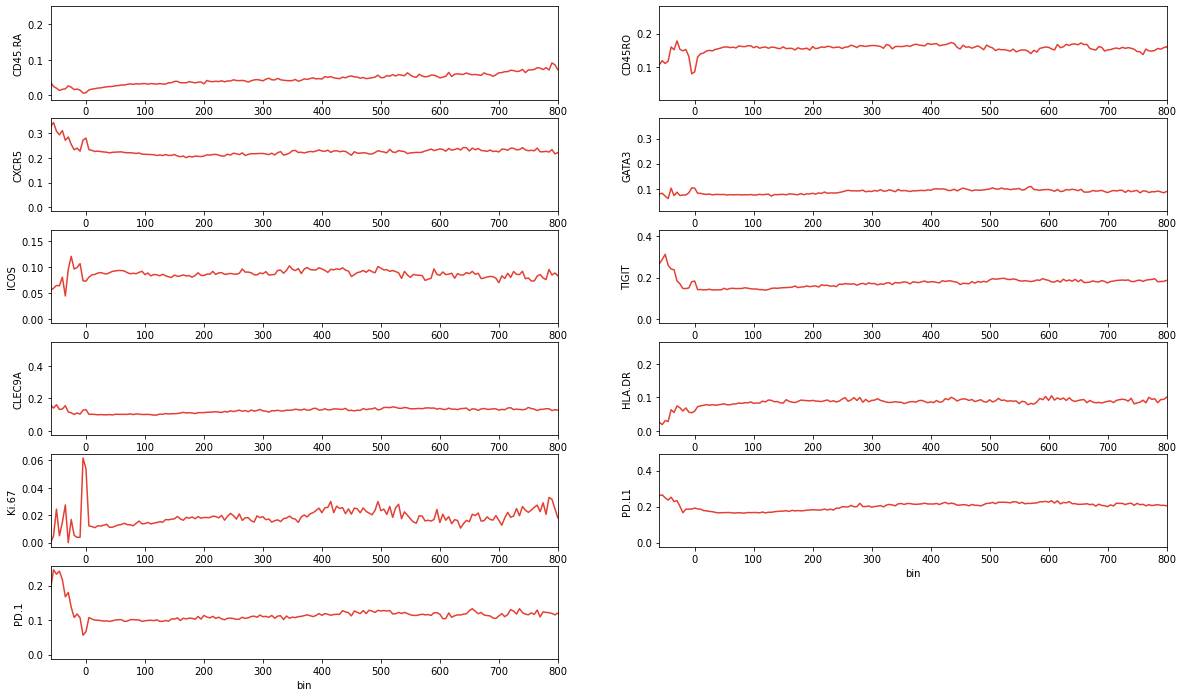

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm

# functional markers
markers = ['CD45.RA','CD45RO','CXCR5','GATA3','ICOS','TIGIT','CLEC9A','HLA.DR','Ki.67','PD.L1','PD.1']

n = len(markers) 
ncols = 2
nrows = n // ncols + (n % ncols > 0) 
# colors = cm.rainbow(np.linspace(0, 1, n))

fig, axs = plt.subplots(nrows, ncols, figsize=(20, nrows*2)) 
axs = axs.flatten() 

# Define the bin size
bin_size = 5

# Create a new column for binned distance.
# Using integer division to bin the values (e.g., distance 2.3 -> 0, 7.1 -> 5, 12.4 -> 10)
result['bin'] = (result['distance_um_rounded'] // bin_size) * bin_size

for i, m in enumerate(markers):
    agg_df = result.groupby('bin')[m].mean().reset_index()
    sns.lineplot(x='bin', y=m, data=agg_df, ax=axs[i], color='#e43f32')
    # axs[i].set_title(m) 
    # Set the upper limit of everything up to 100 um
    current_xlim = axs[i].get_xlim()
    axs[i].set_xlim(-60, 800)

if len(markers) % ncols != 0:
    axs[-1].axis('off')

# plt.subplots_adjust(wspace=0.4, hspace=1)
plt.savefig(f'lineplot_fun_marker_to_distance_um_bin=5.pdf', format='pdf', bbox_inches='tight', dpi = 320)

##### Of certain cell types

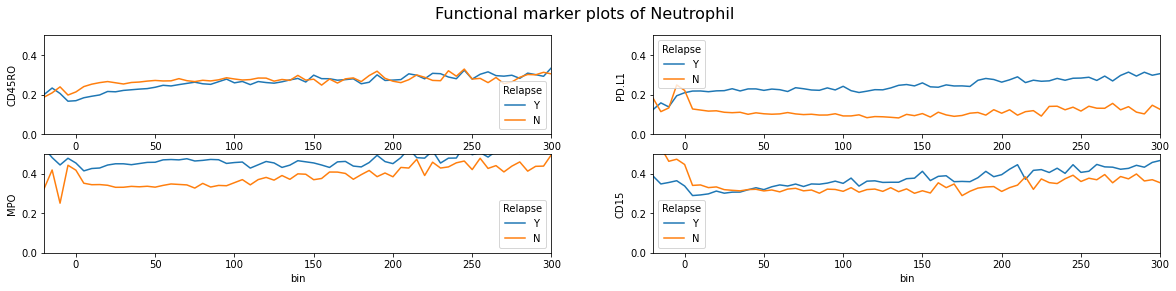

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm

# functional markers
markers = ['CD45RO','PD.L1','MPO','CD15']

celltype_list = ['Neutrophil']#['Other','Neutrophil','M2','CD4','Epithelial','CD8','Neuronal','Endothelial',
                 #'B','Plasmablast','M1','TReg','Monocyte','Lymphatic','NK','Tumor']

# Define the bin size
bin_size = 5

# Create a new column for binned distance.
# Using integer division to bin the values (e.g., distance 2.3 -> 0, 7.1 -> 5, 12.4 -> 10)
result['bin'] = (result['distance_um_rounded'] // bin_size) * bin_size

# Group by both the bin and cell type, then count the number of cells in each group
grouped = result.groupby(['bin', 'cell_cluster']).size().reset_index(name='count')

for i in range(len(celltype_list)):
    curr_table = result[result['cell_cluster']==celltype_list[i]]
    
    n = len(markers) 
    ncols = 2
    nrows = n // ncols + (n % ncols > 0) 
    # colors = cm.rainbow(np.linspace(0, 1, n))

    fig, axs = plt.subplots(nrows, ncols, figsize=(20, nrows*2))
    axs = axs.flatten()
    
    
    curr_result = result[result['cell_cluster']==celltype_list[i]]
    
    for j, m in enumerate(markers):
        agg_df = curr_result.groupby(['bin', 'Relapse'])[m].mean().reset_index()
        sns.lineplot(x='bin', y=m, data=agg_df, ax=axs[j], hue='Relapse')

        # Set the upper limit of everything
        current_xlim = axs[j].get_xlim()
        axs[j].set_xlim(-20, 300)
        axs[j].set_ylim(0, 0.5)
        
    fig.suptitle('Functional marker plots of '+celltype_list[i], fontsize=16)


### Plot the cells around the tumors
Figure S4A

##### By Ratio, divide by Relapse

In [6]:
# this will generate the distance plot (binned by 5 um) of cells in 
# all the FOVs

# Define the bin size
bin_size = 5

# Create a new column for binned distance.
# Using integer division to bin the values (e.g., distance 2.3 -> 0, 7.1 -> 5, 12.4 -> 10)
result['bin'] = (result['distance_um_rounded'] // bin_size) * bin_size

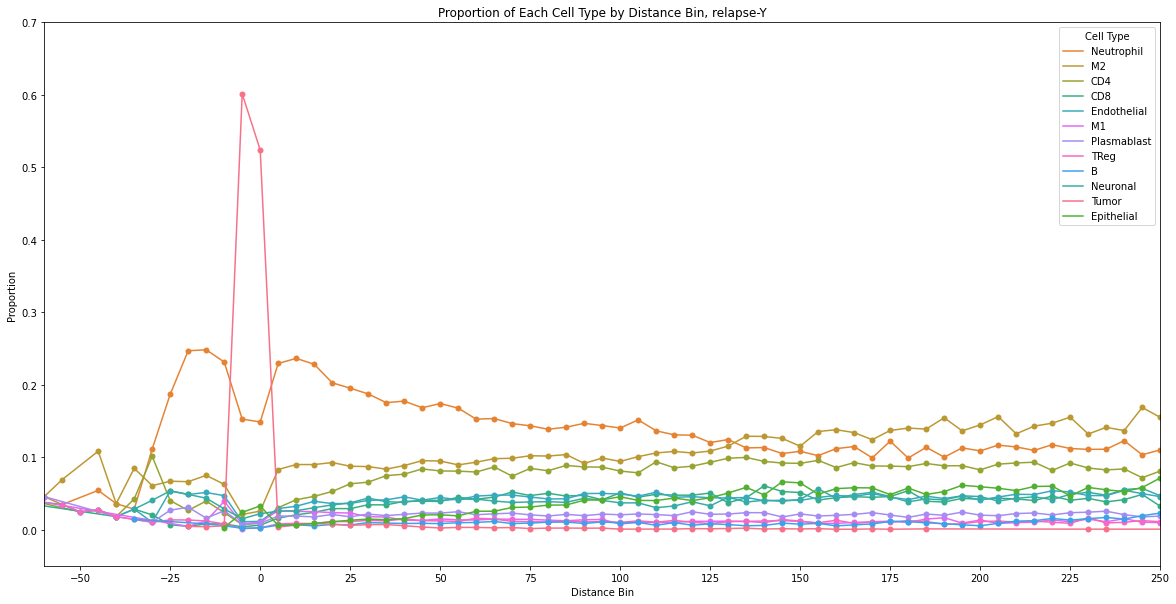

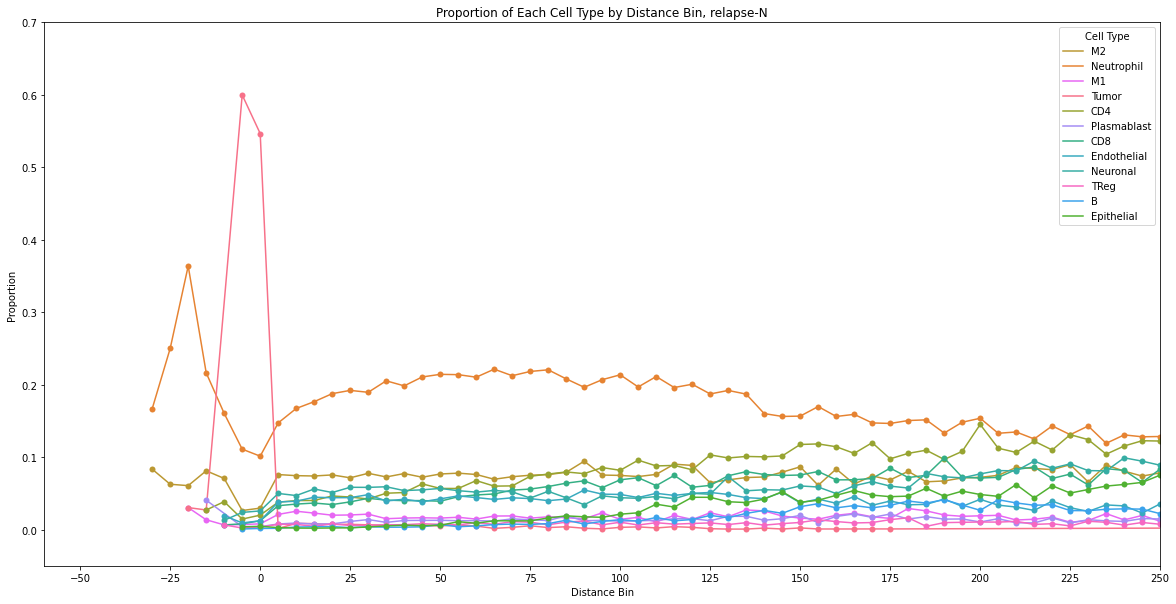

In [7]:
# For plotting, define which cell types you want to include (e.g., excluding 'B')
allowed_types = ['Tumor','Neutrophil','M2','CD4','Epithelial','CD8','Neuronal','Endothelial',
                 'B','Plasmablast','M1','TReg']
                #['Other','Neutrophil','M2','CD4','Epithelial','CD8','Neuronal','Endothelial',
                # 'B','Plasmablast','M1','TReg','Junk','Monocyte','Lymphatic','NK']
        
# Create a dictionary mapping each cell type to one of the 12 colors
palette_dict = dict(zip(allowed_types, sns.color_palette("husl", 12)))


for relapse in ["Y","N"]:
    curr_result = result[result['Relapse']==relapse]

    # Group by both the bin and cell type, then count the number of cells in each group
    grouped = curr_result.groupby(['bin', 'cell_cluster']).size().reset_index(name='count')

    # Calculate the total number of cells in each bin
    total_by_bin = curr_result.groupby('bin').size().reset_index(name='total')

    # Merge the grouped data with the totals
    merged = pd.merge(grouped, total_by_bin, on='bin')

    # Calculate the proportion of each cell type in each bin
    merged['proportion'] = merged['count'] / merged['total']

    # Filter only at the plotting stage. This does not change the denominator of the proportion.
    merged_plot = merged[merged['cell_cluster'].isin(allowed_types)]


    #print(merged)
    # Plotting using Seaborn: each cell type will be a different line
    plt.figure(figsize=(20, 10))
    ax = sns.lineplot(data=merged_plot, x='bin', y='proportion', 
                 hue='cell_cluster', marker='o', markeredgewidth=0,
                 palette=palette_dict       # fixed color mapping
)

    plt.xlabel('Distance Bin')
    plt.ylabel('Proportion')
    plt.title('Proportion of Each Cell Type by Distance Bin, relapse-'+relapse)
    plt.xticks(merged['bin'].unique())
    plt.ylim(-0.05, 0.7)
    plt.xlim(-60, 250)
    ax.set_xticks([-50, -25, 0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250])
    plt.legend(title='Cell Type')

    # Save the current figure as a PDF file
    plt.savefig("lineplot_cellType_um_bin=5_relapse-"+relapse+".pdf", format="pdf")

    plt.show()

#### By Ratio, divide by Relapse
Figure 4B

C:\ProgramData\Anaconda3\lib\site-packages\statsmodels\stats\proportion.py:137: RuntimeWarning: invalid value encountered in sqrt
  dist = crit * np.sqrt(q_ * (1. - q_) / nobs + crit2 / (4. * nobs**2))


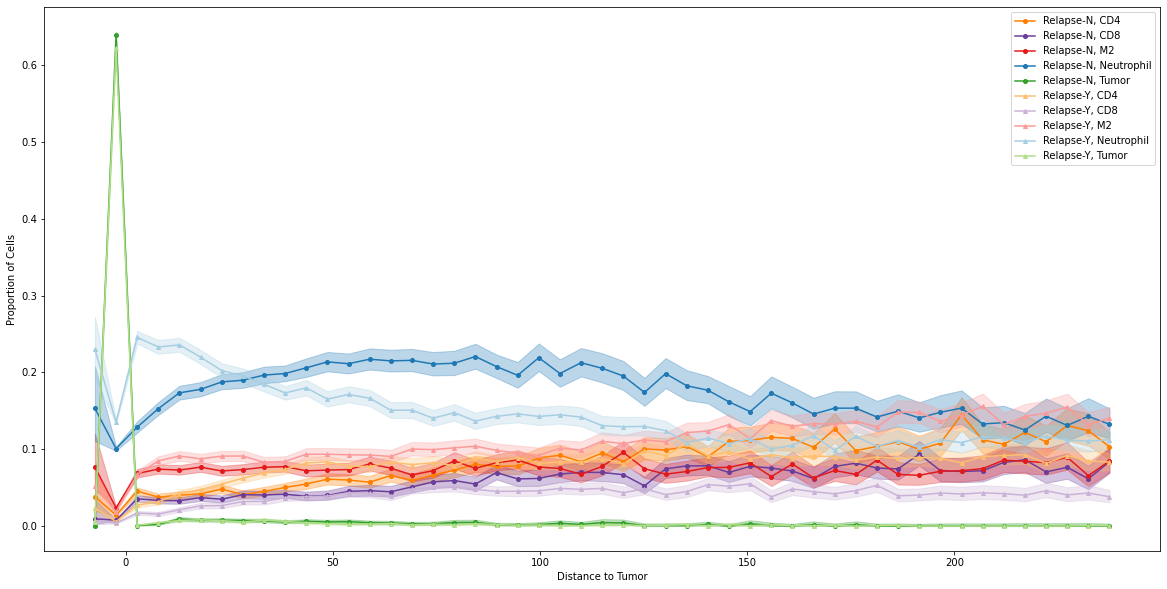

In [16]:
from statsmodels.stats.proportion import proportion_confint

# Define the bin size
#bin_size = 5
# Create a new column for binned distance.
# Using integer division to bin the values (e.g., distance 2.3 -> 0, 7.1 -> 5, 12.4 -> 10)
#result['distance_bin'] = (result['distance_um_rounded'] // bin_size) * bin_size

# Define bins for distance (you can adjust the number of bins as needed)
bins = np.linspace(-10, 240, num=50)
result['distance_bin'] = pd.cut(result['distance_um_rounded'], bins=bins)

# Compute counts per bin for each relapse group and cell type
proportions = result.groupby(['Relapse', 'distance_bin', 'cell_cluster']).size().reset_index(name='count')
# Get total cell counts per relapse group and bin
total_counts = result.groupby(['Relapse', 'distance_bin']).size().reset_index(name='total')
# Merge totals back
proportions = proportions.merge(total_counts, on=['Relapse', 'distance_bin'])
# Calculate proportion
proportions['prop'] = proportions['count'] / proportions['total']

# --- Compute 95% Confidence Interval using the Wilson method ---
def compute_ci(row):
    lower, upper = proportion_confint(row['count'], row['total'], alpha=0.05, method='wilson')
    return pd.Series({'lower': lower, 'upper': upper})

# Apply the function to get CI values
ci_df = proportions.apply(compute_ci, axis=1)
proportions = pd.concat([proportions, ci_df], axis=1)

# Calculate the midpoint of each bin for plotting
proportions['bin_mid'] = proportions['distance_bin'].apply(lambda x: x.mid)

# --- Update 1: Filter out cell types you don't want to plot ---
# For example, if you only want to plot 'B' and 'T' cells:
desired_cell_types = ['Neutrophil','Tumor','M2','CD4','CD8']
                #['Other','Neutrophil','M2','CD4','Epithelial','CD8','Neuronal','Endothelial',
                # 'B','Plasmablast','M1','TReg','Junk','Monocyte','Lymphatic','NK']
proportions = proportions[proportions['cell_cluster'].isin(desired_cell_types)]

# --- Define color mapping using seaborn's "Paired" palette ---
paired_palette = sns.color_palette("Paired", 10)
# Assign colors such that the same cell type has similar colors between relapse groups.
color_dict = {
    ('Y', 'Neutrophil'): paired_palette[0],  # for relapse-Y-Neutrophil
    ('N', 'Neutrophil'): paired_palette[1],  # for relapse-N-Neutrophil
    ('Y', 'Tumor'): paired_palette[2],  # for relapse-Y-Tumor
    ('N', 'Tumor'): paired_palette[3],  # for relapse-N-Tumor
    ('Y', 'M2'): paired_palette[4],  # for relapse-Y-M2
    ('N', 'M2'): paired_palette[5],  # for relapse-N-M2
    ('Y', 'CD4'): paired_palette[6],  # for relapse-Y-CD4
    ('N', 'CD4'): paired_palette[7],  # for relapse-N-CD4
    ('Y', 'CD8'): paired_palette[8],  # for relapse-Y-CD8
    ('N', 'CD8'): paired_palette[9]   # for relapse-N-CD8
}

# Define a dictionary mapping cell types to marker styles
marker_dict = {
    ('Y', 'Neutrophil'): '^',  # for relapse-Y-Neutrophil
    ('Y', 'Tumor'): '^',  # for relapse-Y-Tumor
    ('Y', 'M2'): '^',  # for relapse-Y-M2
    ('Y', 'CD4'): '^',  # for relapse-Y-CD4
    ('Y', 'CD8'): '^',  # for relapse-Y-CD8
}

# Plotting: Create a separate line for each relapse group and cell type
fig, ax = plt.subplots(figsize=(20, 10))
for (relapse, cell_type), group in proportions.groupby(['Relapse', 'cell_cluster']):
    # Get the colors for the cell type
    color = color_dict.get((relapse, cell_type), None)
    # Get the markers for the cell type, default to circle if not specified
    marker = marker_dict.get((relapse, cell_type), 'o')
    
    # Plot the center line
    ax.plot(group['bin_mid'], group['prop'], marker=marker, linestyle='-', markersize=4,
            label=f"Relapse-{relapse}, {cell_type}", color=color)
    # Shade the 95% CI region
    ax.fill_between(group['bin_mid'], group['lower'], group['upper'], color=color, alpha=0.3)

ax.set_xlabel("Distance to Tumor")
ax.set_ylabel("Proportion of Cells")
ax.legend(loc='upper right')

# Save the current figure as a PDF file
plt.savefig("lineplot_cellType_um_bin=5_withCI-shadow.pdf", format="pdf")

plt.show()

### Based on the plot, now divide the neutrophils in the population by relapse
consider simple division or by distance as we can see some variation

Neutrophil cell ratio (of all celltypes) plots around the tumor

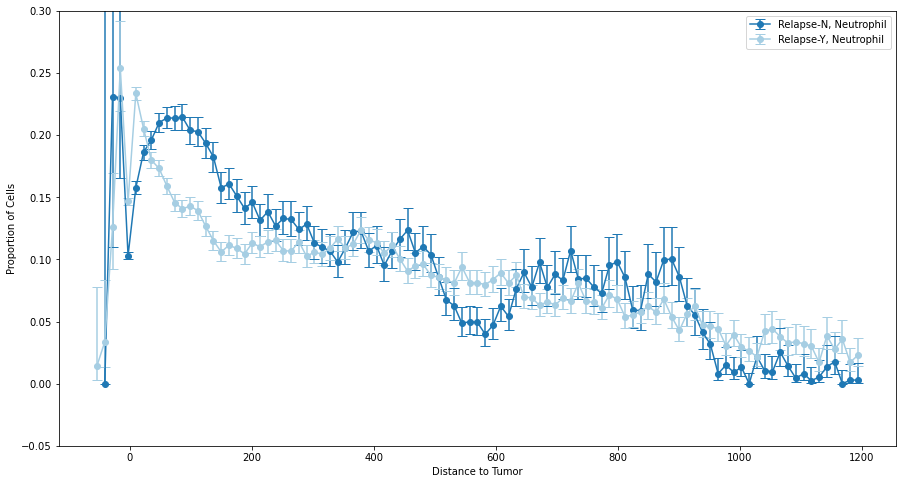

Neutrophil cell counts plots around the tumor

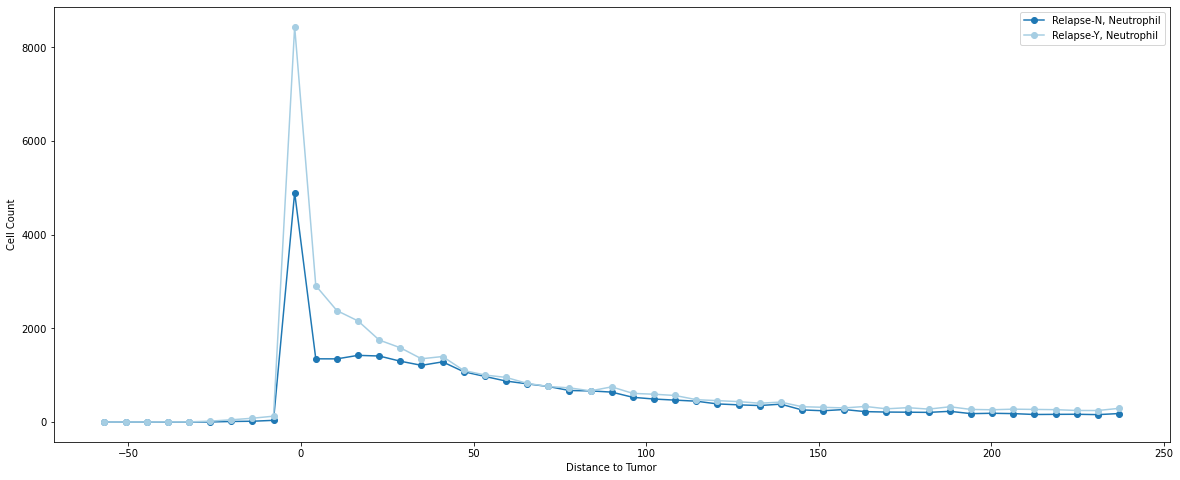

In [6]:
# get the neutrophils
result_neu = result[result['cell_cluster']=='Neutrophil']
# we have 94489 neutrophils, 55425 belong to relapsed, 39064 belong to non-relapsed
result_neu['Relapse'].value_counts()

Y    53288
N    34641
Name: Relapse, dtype: int64

In [7]:
# divide the neutrophils by distance to the tumors
# But at what distance??
# (we here have PDAC, so not necessary to use the complicated tumor score method)
distance_close_low = 0 # in um
distance_close_up = 25 # in um
distance_far_low = 25 # in um
distance_far_up = 100 # in um

neutro_close = result_neu[(result_neu['distance_um'] > distance_close_low) & (result_neu['distance_um'] <= distance_close_up)]
print('Neutrophil close has '+str(len(neutro_close))+' cells, '+str(len(neutro_close)/87929)+' of all the Neutrophils')

neutro_far = result_neu[(result_neu['distance_um'] > distance_far_low) & (result_neu['distance_um'] <= distance_far_up)]
print('Neutrophil far has '+str(len(neutro_far))+' cells, '+str(len(neutro_far)/87929)+' of all the Neutrophils')

Neutrophil close has 22592 cells, 0.25693457221167076 of all the Neutrophils
Neutrophil far has 23032 cells, 0.2619386095599859 of all the Neutrophils


#### Focus on Neutrophils, plot divide by Relapse or not
Figure 4C

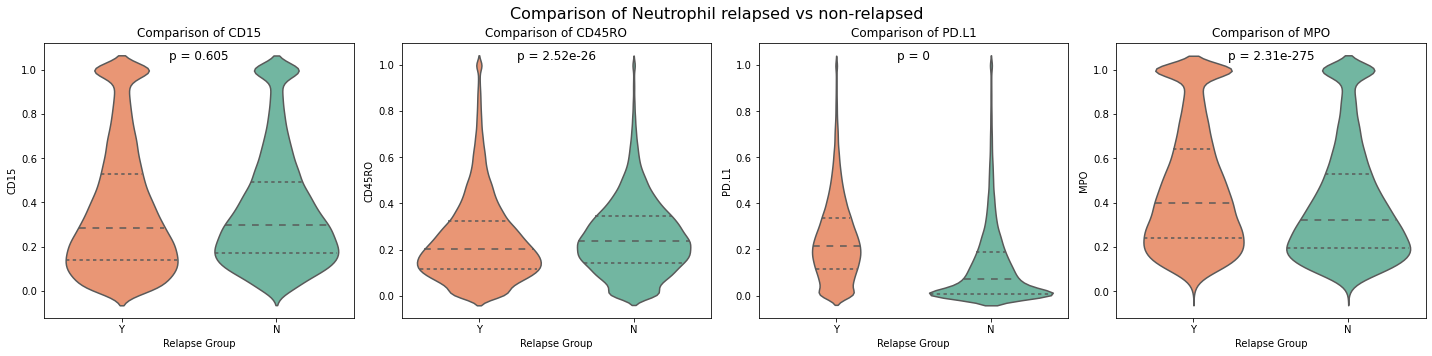

In [8]:
from scipy.stats import ttest_ind  # Use mannwhitneyu if data is non-normal

# List of parameters to compare between relapse groups
parameters = ['CD15','CD45RO','PD.L1','MPO']#['CD45.RA','CD45RO','HLA.DR','Ki.67','PD.1','PD.L1','MPO','CD11b','CD15','CD16','CD169']

# Create subplots - one for each parameter
n2 = len(parameters) 
ncols = 4
nrows = n2 // ncols + (n2 % ncols > 0) 
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*5)) 
axes = axes.flatten() 

for ax, param in zip(axes, parameters):
    # Plot boxplot and overlay with a swarmplot to show individual points
    #sns.boxplot(x='Relapse', y=param, data=result_neu, ax=ax, palette="Set2")
    #sns.swarmplot(x='relapse', y=param, data=result_neu, ax=ax, color='.25')
    # Plot the violin plot
    sns.violinplot(x='Relapse', y=param, data=result_neu, ax=ax, 
                   palette=sns.color_palette("Set2", n_colors=2)[::-1], #palette="Set2", #
                   inner='quartile', order=['Y', 'N'])
    
    # Statistical test: t-test between relapse groups
    group_Y = result_neu[result_neu['Relapse'] == 'Y'][param]
    group_N = result_neu[result_neu['Relapse'] == 'N'][param]
    stat, p_val = ttest_ind(group_Y, group_N)
    # If data is non-normal, you might use:
    # from scipy.stats import mannwhitneyu
    # stat, p_val = mannwhitneyu(group_Y, group_N)
    
    # Annotate the p-value on the plot using axis coordinates (0.5 is center, 0.95 is near the top)
    p_text = f"p = {p_val:.3g}"
    ax.text(0.5, 0.95, p_text, transform=ax.transAxes, ha='center', va='center', fontsize=12)
    
    ax.set_title(f'Comparison of {param}')
    ax.set_xlabel('Relapse Group')
    #ax.set_ylim(-0.05, 0.1)
    ax.set_ylabel(param)

plt.tight_layout()
fig.suptitle('Comparison of Neutrophil relapsed vs non-relapsed', fontsize=16)
plt.subplots_adjust(top=0.88) # Adjust top to make space for suptitle

# Save the current figure as a PDF file
plt.savefig("violinplot_Neu_relapsed vs non-relapsed.pdf", format="pdf")
plt.savefig("violinplot_Neu_relapsed vs non-relapsed.svg", format="svg")

plt.show()

#### Focus on Neutrophils, plot divide by Near or Far

<ipython-input-9-4ff69dee4165>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


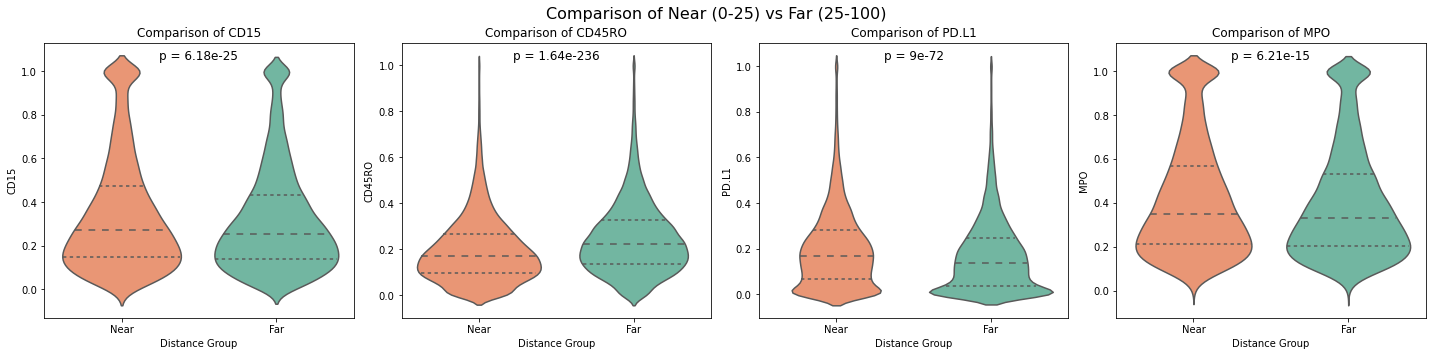

In [9]:
from scipy.stats import ttest_ind  # Use mannwhitneyu if data is non-normal

# List of parameters to compare between relapse groups
parameters = ['CD15','CD45RO','PD.L1','MPO']#['CD45.RA','CD45RO','HLA.DR','Ki.67','PD.1','PD.L1','MPO','CD11b','CD15','CD16','CD169']

distance_close_low = 0 # in um
distance_close_up = 25 # in um
distance_far_low = 25 # in um
distance_far_up = 100 # in um

# Define conditions
conditions = [
    (result_neu['distance_to_tumor'] > distance_close_low) & (result_neu['distance_to_tumor'] <= distance_close_up),
    (result_neu['distance_to_tumor'] > distance_far_low) & (result_neu['distance_to_tumor'] <= distance_far_up)
]
# Define corresponding choices
choices = ['Near', 'Far']
# Create a new column with the category based on the conditions, defaulting to 'Undefined'
result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')

# Filter out the Undefined category
plot_data = result_neu[result_neu['distance_category'].isin(['Near', 'Far'])]

# Create subplots - one for each parameter
n2 = len(parameters) 
ncols = 4
nrows = n2 // ncols + (n2 % ncols > 0) 
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*5)) 
axes = axes.flatten() 

for ax, param in zip(axes, parameters):
    # Plot boxplot and overlay with a swarmplot to show individual points
    #sns.boxplot(x='Relapse', y=param, data=result_neu, ax=ax, palette="Set2")
    #sns.swarmplot(x='relapse', y=param, data=result_neu, ax=ax, color='.25')
    # Plot the violin plot
    sns.violinplot(x='distance_category', y=param, data=plot_data , ax=ax, 
                   palette=sns.color_palette("Set2", n_colors=2)[::-1], #palette="Set2", 
                   inner='quartile', order = ['Near', 'Far'])
    
    # Statistical test: t-test between relapse groups
    group_N = result_neu[result_neu['distance_category'] == 'Near'][param]
    group_F = result_neu[result_neu['distance_category'] == 'Far'][param]
    stat, p_val = ttest_ind(group_N, group_F)
    # If data is non-normal, you might use:
    # from scipy.stats import mannwhitneyu
    # stat, p_val = mannwhitneyu(group_Y, group_N)
    
    # Annotate the p-value on the plot using axis coordinates (0.5 is center, 0.95 is near the top)
    p_text = f"p = {p_val:.3g}"
    ax.text(0.5, 0.95, p_text, transform=ax.transAxes, ha='center', va='center', fontsize=12)
    
    ax.set_title(f'Comparison of {param}')
    ax.set_xlabel('Distance Group')
    #ax.set_ylim(-0.05, 0.1)
    ax.set_ylabel(param)

plt.tight_layout()
fig.suptitle('Comparison of Near ('+str(distance_close_low)+'-'+str(distance_close_up)+') vs Far ('+str(distance_far_low)+'-'+str(distance_far_up)+')', fontsize=16)
plt.subplots_adjust(top=0.88) # Adjust top to make space for suptitle

# Save the current figure as a PDF file
plt.savefig("violinplot_Neu_Near ("+str(distance_close_low)+"-"+str(distance_close_up)+" vs Far ("+str(distance_far_low)+"-"+str(distance_far_up)+").pdf", format="pdf")
plt.savefig("violinplot_Neu_Near ("+str(distance_close_low)+"-"+str(distance_close_up)+" vs Far ("+str(distance_far_low)+"-"+str(distance_far_up)+").svg", format="svg")

plt.show()

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


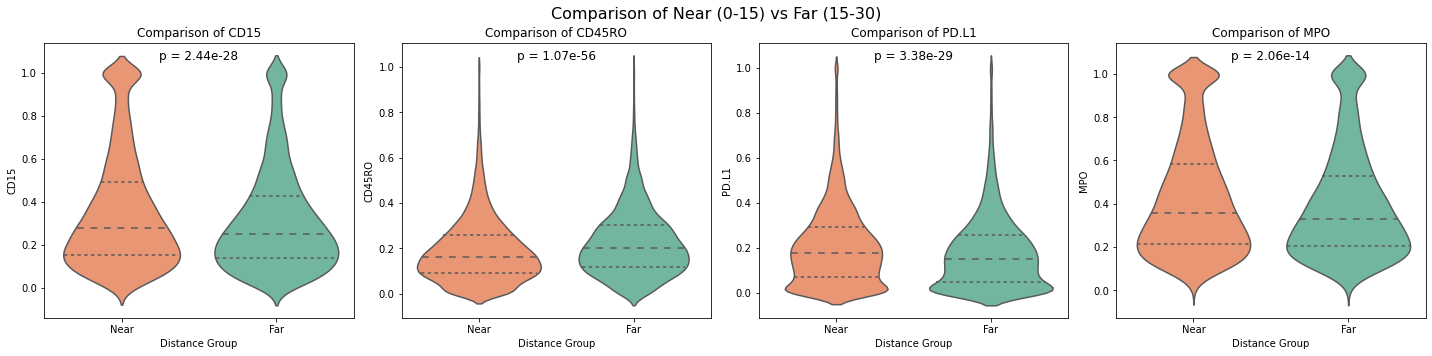

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


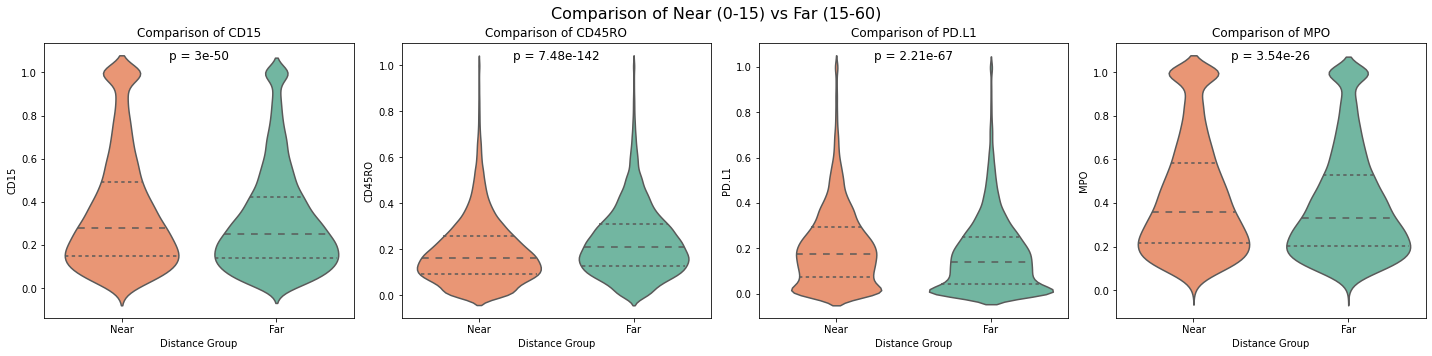

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


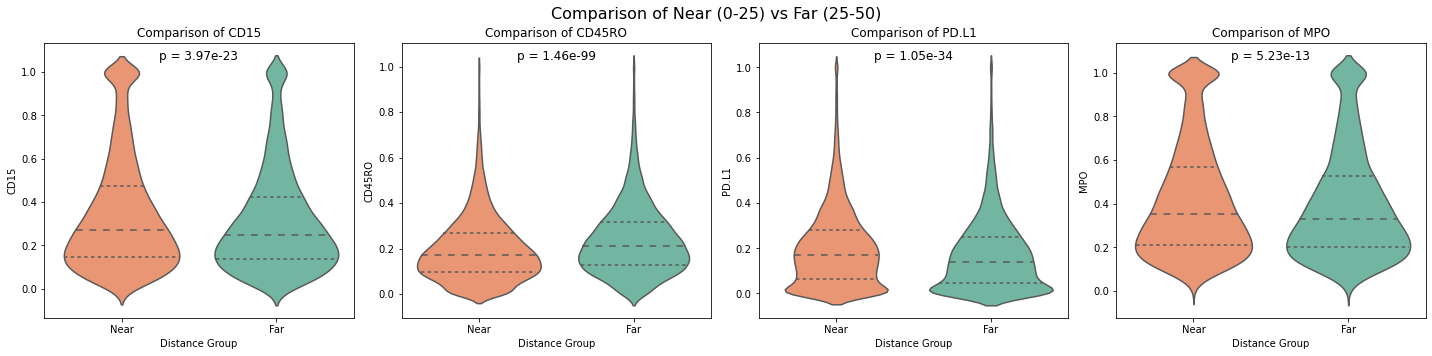

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


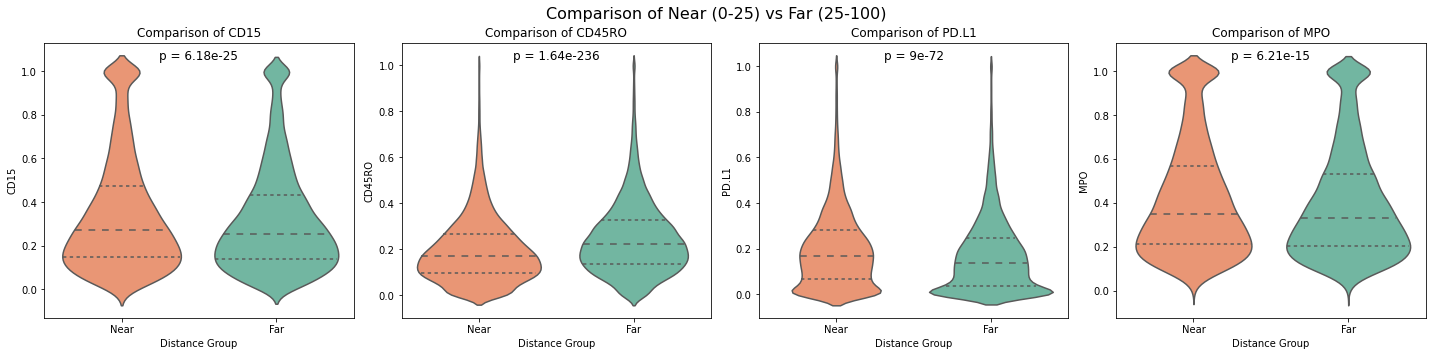

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


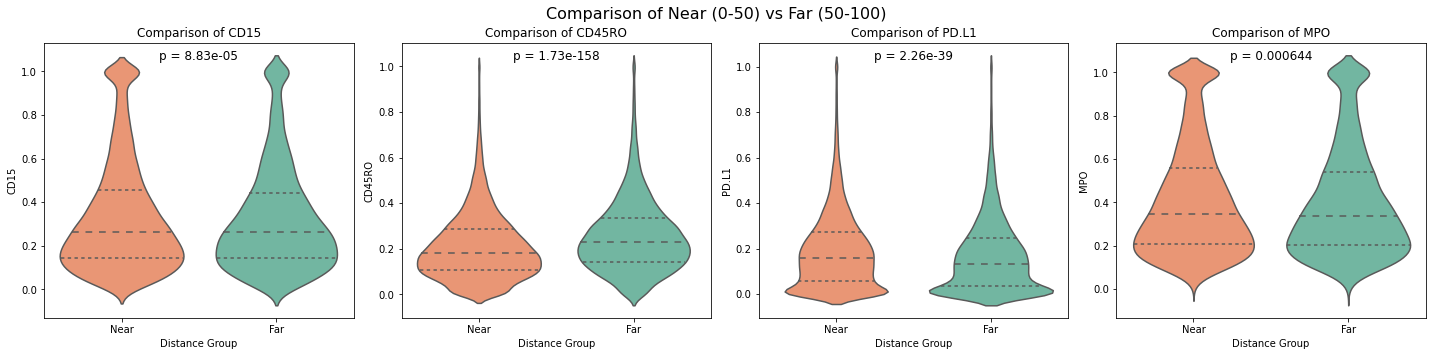

<ipython-input-10-940382e340e5>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


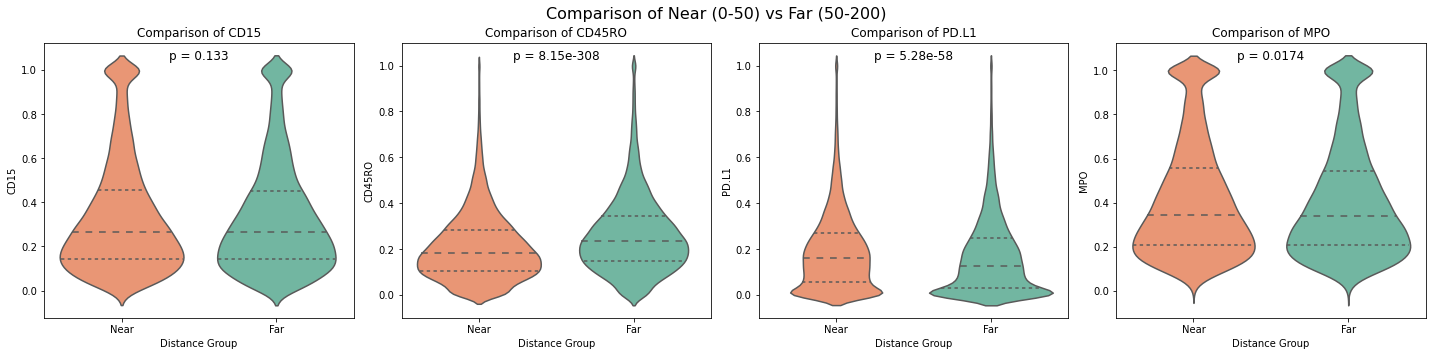

In [10]:
from scipy.stats import ttest_ind  # Use mannwhitneyu if data is non-normal

# List of parameters to compare between relapse groups
parameters = ['CD15','CD45RO','PD.L1','MPO']#['CD45.RA','CD45RO','HLA.DR','Ki.67','PD.1','PD.L1','MPO','CD11b','CD15','CD16','CD169']

dists_list = [(0,15,15,30),(0,15,15,60),
              (0,25,25,50),(0,25,25,100),
              (0,50,50,100),(0,50,50,200)]

for dist_thres in dists_list:
    # Define conditions
    conditions = [
        (result_neu['distance_to_tumor'] > dist_thres[0]) & (result_neu['distance_to_tumor'] <= dist_thres[1]),
        (result_neu['distance_to_tumor'] > dist_thres[2]) & (result_neu['distance_to_tumor'] <= dist_thres[3])
    ]
    # Define corresponding choices
    choices = ['Near', 'Far']
    # Create a new column with the category based on the conditions, defaulting to 'Undefined'
    result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')

    # Filter out the Undefined category
    plot_data = result_neu[result_neu['distance_category'].isin(['Near', 'Far'])]

    # Create subplots - one for each parameter
    n2 = len(parameters) 
    ncols = 4
    nrows = n2 // ncols + (n2 % ncols > 0) 
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*5)) 
    axes = axes.flatten() 

    for ax, param in zip(axes, parameters):
        # Plot boxplot and overlay with a swarmplot to show individual points
        #sns.boxplot(x='Relapse', y=param, data=result_neu, ax=ax, palette="Set2")
        #sns.swarmplot(x='relapse', y=param, data=result_neu, ax=ax, color='.25')
        # Plot the violin plot
        sns.violinplot(x='distance_category', y=param, data=plot_data , ax=ax, 
                       palette=sns.color_palette("Set2", n_colors=2)[::-1], #palette="Set2", 
                       inner='quartile', order = ['Near', 'Far'])

        # Statistical test: t-test between relapse groups
        group_N = result_neu[result_neu['distance_category'] == 'Near'][param]
        group_F = result_neu[result_neu['distance_category'] == 'Far'][param]
        stat, p_val = ttest_ind(group_N, group_F)
        # If data is non-normal, you might use:
        # from scipy.stats import mannwhitneyu
        # stat, p_val = mannwhitneyu(group_Y, group_N)

        # Annotate the p-value on the plot using axis coordinates (0.5 is center, 0.95 is near the top)
        p_text = f"p = {p_val:.3g}"
        ax.text(0.5, 0.95, p_text, transform=ax.transAxes, ha='center', va='center', fontsize=12)

        ax.set_title(f'Comparison of {param}')
        ax.set_xlabel('Distance Group')
        #ax.set_ylim(-0.05, 0.1)
        ax.set_ylabel(param)

    plt.tight_layout()
    fig.suptitle('Comparison of Near ('+str(dist_thres[0])+'-'+str(dist_thres[1])+') vs Far ('+str(dist_thres[2])+'-'+str(dist_thres[3])+')', fontsize=16)
    plt.subplots_adjust(top=0.88) # Adjust top to make space for suptitle

    # Save the current figure as a PDF file
    plt.savefig("violinplot_Neu_Near ("+str(dist_thres[0])+'-'+str(dist_thres[1])+') vs Far ('+str(dist_thres[2])+'-'+str(dist_thres[3])+").pdf", format="pdf")
    plt.savefig("violinplot_Neu_Near ("+str(dist_thres[0])+'-'+str(dist_thres[1])+') vs Far ('+str(dist_thres[2])+'-'+str(dist_thres[3])+").svg", format="svg")

    plt.show()

#### Now, lets further break down the dataset into smaller things
Figure S4B

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


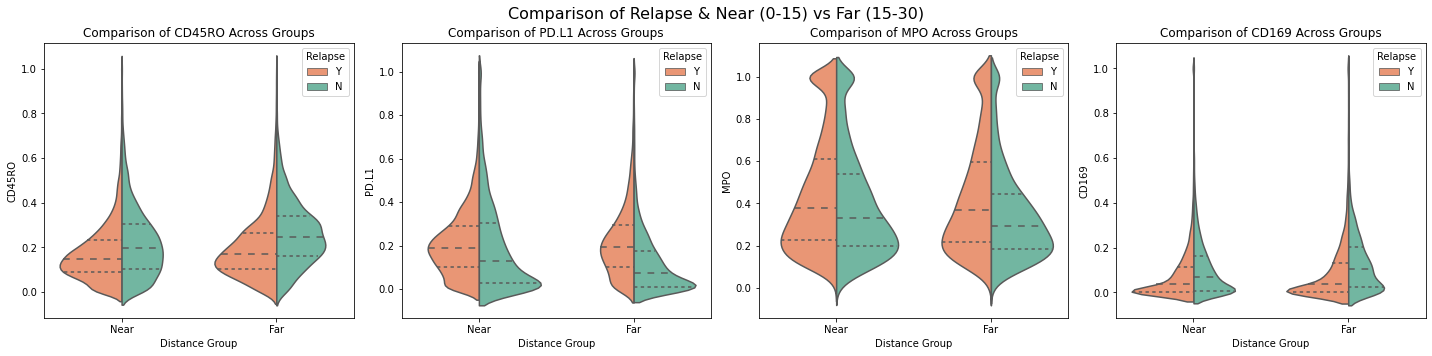

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


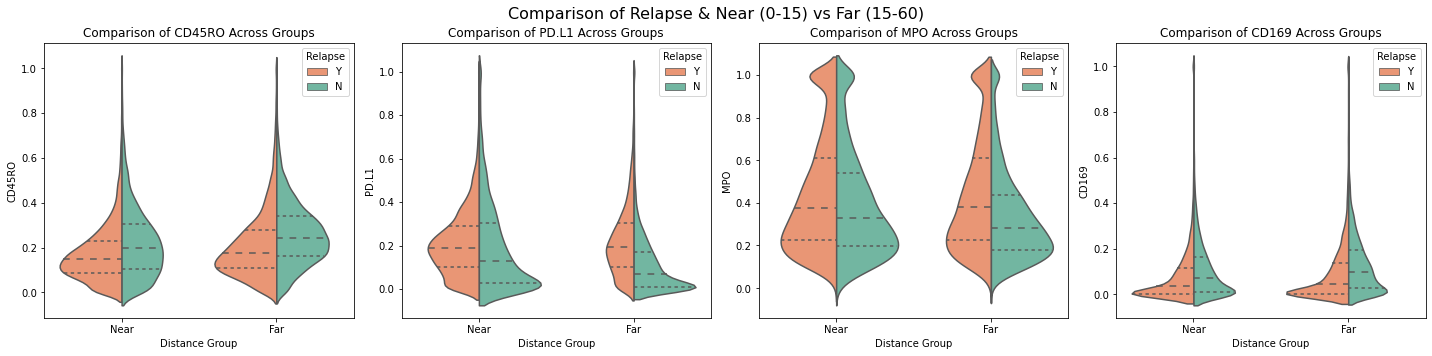

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


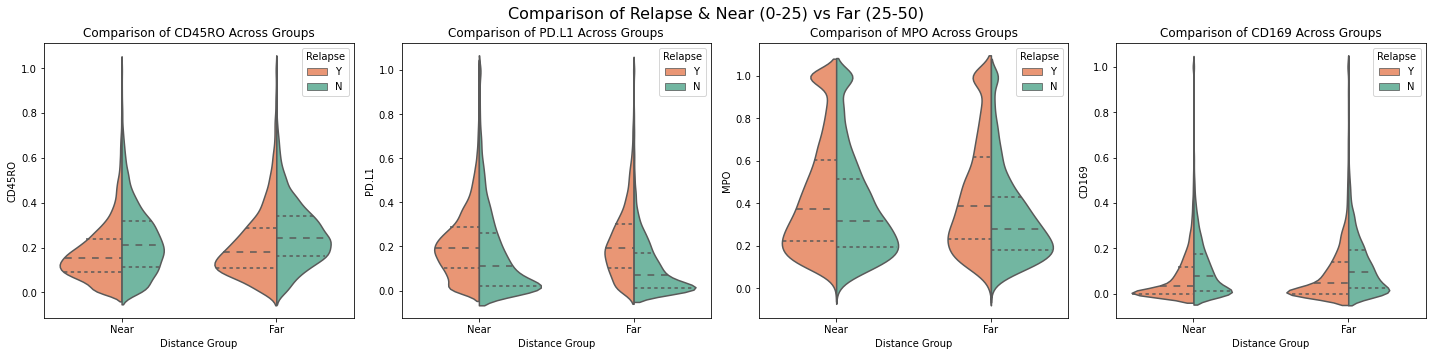

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


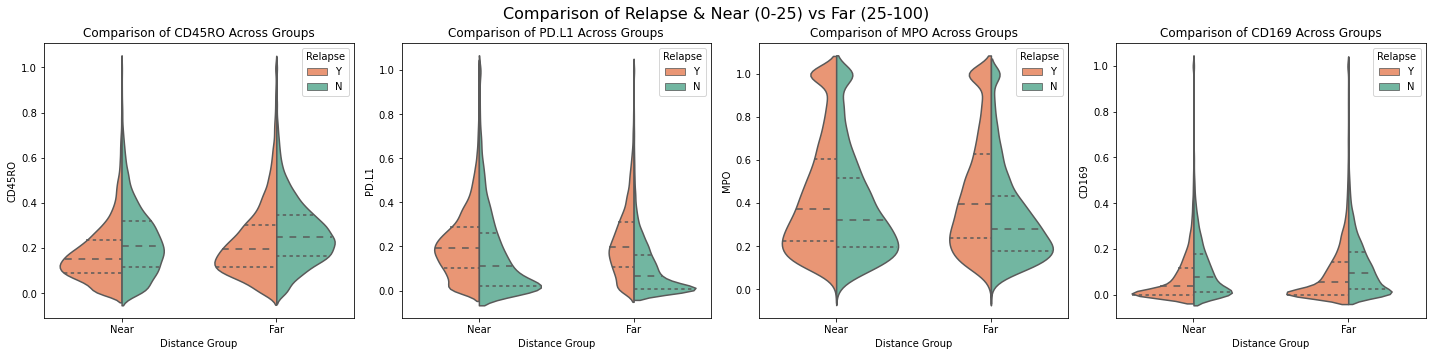

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


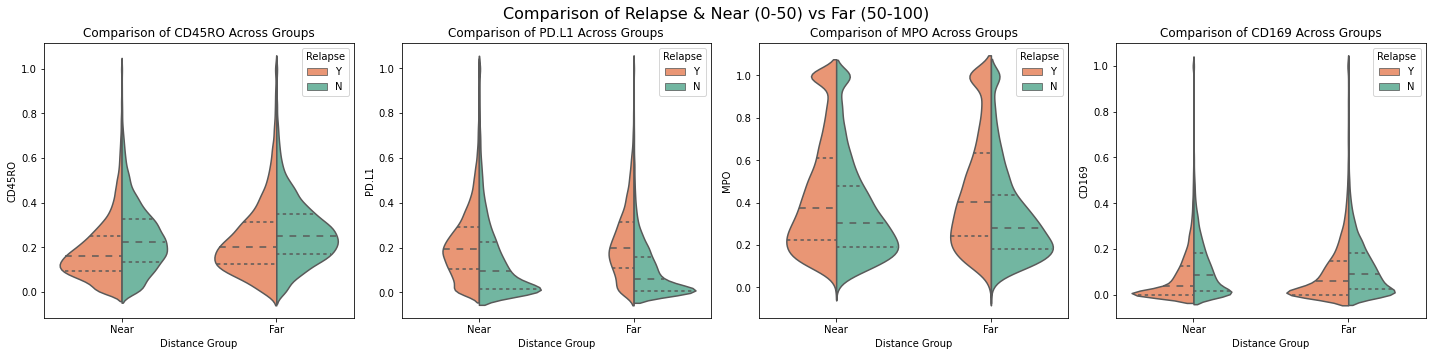

<ipython-input-45-7fdc7f598c62>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')


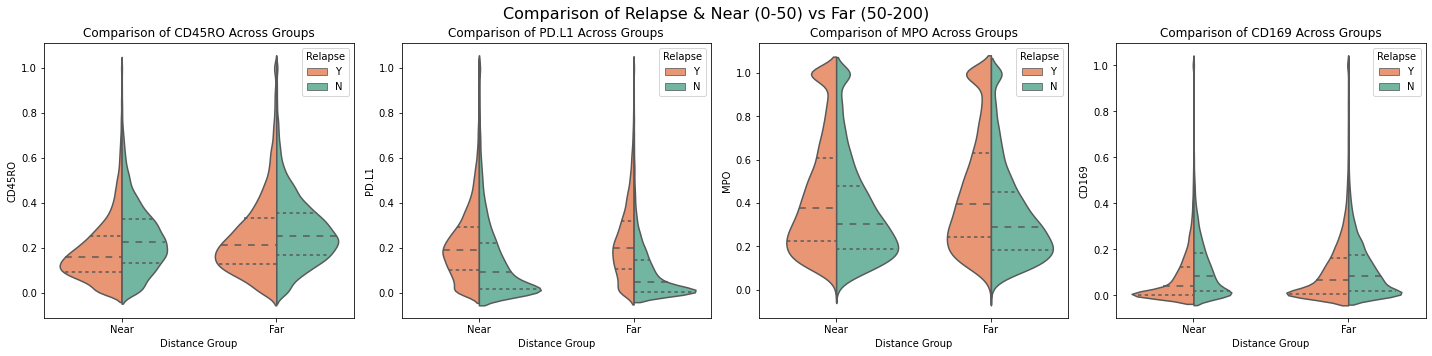

In [45]:
# List of parameters to compare between relapse groups
parameters = ['CD45RO','PD.L1','MPO','CD169']#['CD45.RA','CD45RO','HLA.DR','Ki.67','PD.1','PD.L1','MPO','CD11b','CD15','CD16','CD169']

dists_list = [(0,15,15,30),(0,15,15,60),
              (0,25,25,50),(0,25,25,100),
              (0,50,50,100),(0,50,50,200)]

for dist_thres in dists_list:
    # Define conditions
    conditions = [
        (result_neu['distance_to_tumor'] > dist_thres[0]) & (result_neu['distance_to_tumor'] <= dist_thres[1]),
        (result_neu['distance_to_tumor'] > dist_thres[2]) & (result_neu['distance_to_tumor'] <= dist_thres[3])
    ]
    # Define corresponding choices
    choices = ['Near', 'Far']
    # Create a new column with the category based on the conditions, defaulting to 'Undefined'
    result_neu['distance_category'] = np.select(conditions, choices, default='Undefined')

    # Filter out the Undefined category
    plot_data = result_neu[result_neu['distance_category'].isin(['Near', 'Far'])]

    # Create subplots - one for each parameter
    n2 = len(parameters) 
    ncols = 4
    nrows = n2 // ncols + (n2 % ncols > 0) 
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*5)) 
    axes = axes.flatten() 

    for ax, param in zip(axes, parameters):
        # Create a violin plot with relapse on the x-axis and distance_category as hue
        sns.violinplot(x='distance_category', y=param, hue='Relapse', data=plot_data, 
                       ax=ax, split=True, 
                       palette=sns.color_palette("Set2", n_colors=2)[::-1], #palette="Set2", 
                       inner='quartile',
                       order=['Near', 'Far'])
        
        # Remove duplicate legends (since both plots add one)
        handles, labels = ax.get_legend_handles_labels()
        # Typically the handles are duplicated, so take only the first two (for 'Near' and 'Far')
        ax.legend(handles[:2], labels[:2], title="Relapse", loc='upper right')

        ax.set_title(f'Comparison of {param} Across Groups')
        ax.set_xlabel('Distance Group')
        ax.set_ylabel(param)

    plt.tight_layout()
    fig.suptitle('Comparison of Relapse & Near ('+str(dist_thres[0])+'-'+str(dist_thres[1])+') vs Far ('+str(dist_thres[2])+'-'+str(dist_thres[3])+')', fontsize=16)
    plt.subplots_adjust(top=0.88) # Adjust top to make space for suptitle
    plt.show()